# Ensemble methods

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/03-supervised/ensembles/ensembles-notebook.ipynb)

Companion notebook for the *Ensemble methods* slides. Each idea is written first by hand
with NumPy and then with the scikit-learn class that does the same job.

**Data:** the Breast Cancer Wisconsin data (569 tumors, 30 measurements, malignant or benign).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import ensemble, tree
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TREE_COUNT = 100
ROUNDS = 5
MIN_AGREEMENT = 0.95

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
rng = np.random.default_rng(RANDOM_STATE)
n = len(y_train)

## 1. A bootstrap sample

Draw $n$ rows with replacement. Each row is left out with probability $(1 - 1/n)^n \approx 0.368$.

In [2]:
sample = rng.integers(0, n, size=n)
left_out = 1 - len(np.unique(sample)) / n
print(f"left out: {left_out:.3f} | formula: {(1 - 1 / n) ** n:.3f}")

left out: 0.374 | formula: 0.367


## 2. Bagging

Train one tree on each of $B$ bootstrap samples and let them vote: $\hat{y} = \arg\max_c \sum_{b=1}^{B} \mathbb{I}(\hat{f}_b(\mathbf{x}) = c)$.
The base trees come from scikit-learn; the bagging is ours.

In [3]:
class BaggingClassifier:
    """Majority vote of decision trees, each trained on its own bootstrap sample."""

    def __init__(self, n_estimators: int = 10, random_state: int | None = None):
        self.n_estimators, self.random_state = n_estimators, random_state

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        self.classes_ = np.unique(y)
        self.estimators_ = []
        for _ in range(self.n_estimators):
            sample = rng.integers(0, len(X), size=len(X))
            self.estimators_.append(tree.DecisionTreeClassifier().fit(X[sample], y[sample]))
        return self

    def predict(self, X):
        votes = np.array([estimator.predict(X) for estimator in self.estimators_])
        return self.classes_[np.argmax([(votes == c).sum(axis=0) for c in self.classes_], axis=0)]

    def score(self, X, y):
        return np.mean(self.predict(X) == y)


by_hand = BaggingClassifier(n_estimators=TREE_COUNT, random_state=RANDOM_STATE).fit(X_train, y_train)

The two versions draw different random samples, so their trees differ. Instead of equal predictions we ask that
they agree on at least 95% (`MIN_AGREEMENT`) of the test tumors.

In [4]:
single_tree = tree.DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
bagging = ensemble.BaggingClassifier(tree.DecisionTreeClassifier(), n_estimators=TREE_COUNT,
                                     random_state=RANDOM_STATE).fit(X_train, y_train)

agreement = np.mean(by_hand.predict(X_test) == bagging.predict(X_test))
print(f"test accuracy: one tree {single_tree.score(X_test, y_test):.3f}, "
      f"bagging by hand {by_hand.score(X_test, y_test):.3f}, scikit-learn {bagging.score(X_test, y_test):.3f}")
print(f"agreement {agreement:.3f} | at least {MIN_AGREEMENT}:", agreement >= MIN_AGREEMENT)

test accuracy: one tree 0.918, bagging by hand 0.947, scikit-learn 0.947
agreement 0.988 | at least 0.95: True


## 3. Random forests

A random forest is bagging plus one more twist: each split only looks at a random subset of
about $\sqrt{d}$ features, so the trees differ more.

In [5]:
forest = ensemble.RandomForestClassifier(n_estimators=TREE_COUNT, max_features="sqrt",
                                         random_state=RANDOM_STATE).fit(X_train, y_train)
print(f"features per split: {int(np.sqrt(X.shape[1]))} of {X.shape[1]} | test accuracy {forest.score(X_test, y_test):.3f}")

features per split: 5 of 30 | test accuracy 0.936


## 4. Boosting

AdaBoost trains one-split trees $h_m$ one after another, with labels $y_i \in \{-1, +1\}$.
A tree with weighted error $\varepsilon_m$ gets the vote $\alpha_m = \frac{1}{2}\ln\frac{1 - \varepsilon_m}{\varepsilon_m}$,
and the weights become $w_i \leftarrow w_i\, e^{-\alpha_m y_i h_m(\mathbf{x}_i)}$, rescaled to add up to 1:
the examples it got wrong weigh more in the next round. The prediction is $\operatorname{sign}\big(\sum_m \alpha_m h_m(\mathbf{x})\big)$.

In [6]:
class AdaBoostClassifier:
    """AdaBoost for two classes: a weighted vote of one-split trees."""

    def __init__(self, n_estimators: int = 50):
        self.n_estimators = n_estimators

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        signs = np.where(y == self.classes_[1], 1, -1)
        weights = np.full(len(X), 1 / len(X))
        self.estimators_, self.estimator_weights_, self.estimator_errors_ = [], [], []
        for _ in range(self.n_estimators):
            stump = tree.DecisionTreeClassifier(max_depth=1).fit(X, signs, sample_weight=weights)
            h = stump.predict(X)
            error = np.sum(weights[h != signs])
            alpha = 0.5 * np.log((1 - error) / error)
            weights = weights * np.exp(-alpha * signs * h)
            weights /= weights.sum()
            self.estimators_.append(stump)
            self.estimator_weights_.append(alpha)
            self.estimator_errors_.append(error)
        return self

    def decision_function(self, X):
        return sum(alpha * stump.predict(X) for alpha, stump in zip(self.estimator_weights_, self.estimators_))

    def predict(self, X):
        return self.classes_[(self.decision_function(X) > 0).astype(int)]

    def score(self, X, y):
        return np.mean(self.predict(X) == y)


by_hand = AdaBoostClassifier(n_estimators=ROUNDS).fit(X_train, y_train)
print("errors:", np.round(by_hand.estimator_errors_, 3), "| votes:", np.round(by_hand.estimator_weights_, 3))

errors: [0.073 0.104 0.147 0.229 0.256] | votes: [1.272 1.076 0.878 0.608 0.534]


scikit-learn uses the vote $\ln\frac{1 - \varepsilon_m}{\varepsilon_m}$, twice ours. Doubling every vote does not change
any sign, so the predictions are the same.

In [7]:
boosting = ensemble.AdaBoostClassifier(n_estimators=ROUNDS, random_state=RANDOM_STATE).fit(X_train, y_train)
print("same errors:", np.allclose(by_hand.estimator_errors_, boosting.estimator_errors_))
print("votes are half:", np.allclose(by_hand.estimator_weights_, boosting.estimator_weights_ / 2))
print("same predictions:", np.array_equal(by_hand.predict(X_test), boosting.predict(X_test)))

same errors: True
votes are half: True
same predictions: True


## 5. Comparing them

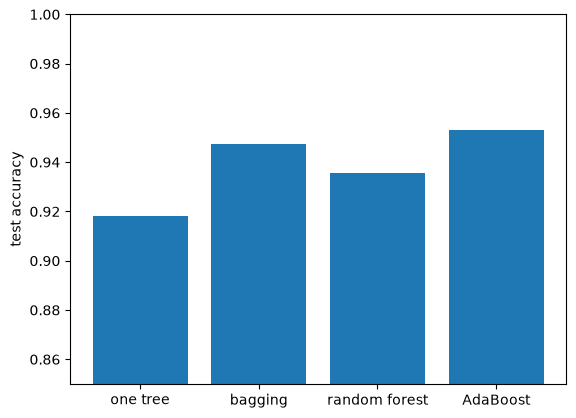

In [8]:
boosting = ensemble.AdaBoostClassifier(n_estimators=TREE_COUNT, random_state=RANDOM_STATE).fit(X_train, y_train)
names = ["one tree", "bagging", "random forest", "AdaBoost"]
accuracies = [model.score(X_test, y_test) for model in [single_tree, bagging, forest, boosting]]
plt.bar(names, accuracies)
plt.ylim(0.85, 1)
plt.ylabel("test accuracy")
plt.show()

## Exercises

1. Repeat section 2 with 1, 5, 25 and 100 trees. How does the accuracy change?
2. Set `max_features=None` in the forest. It is now plain bagging; compare the accuracy.
3. Train the AdaBoost of section 4 with 1, 5, 25 and 100 rounds. Does the training accuracy keep rising? And the test accuracy?